# Paleta ao longo do tempo

Definindo com a música vai influênciar nas cores das partículas.

A cor é calculada em `map_features_to_color_params`:

- **matiz:** média circular das 12 classes de altura, ponderada pelo chroma;
- **luminosidade:** centroide espectral (sons brilhantes, cores claras);
- **croma (saturação):** RMS, e cinza no silêncio.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.color import oklch_to_srgb
from src.config import load_config
from src.features import load_features
from src.mapping import map_features_to_color_params, pitch_class_hues

config = load_config()
tracks = sorted((ROOT / "data/audio/songs").glob("*.wav")) + sorted((ROOT / "data/audio/synthetic").glob("*.wav"))
colors = {path.stem: map_features_to_color_params(load_features(path), config) for path in tracks}

SURFACE, INK, INK_2, MUTED, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
})

## As 12 notas

As classes de altura seguem a ordem do *clavecin oculaire* de Castel: Dó azul, passando por verde, amarelo e laranja até Sol vermelho, e depois violeta. Cada semitom gira o matiz 30°. Abaixo, cada nota com luminosidade e croma médios.

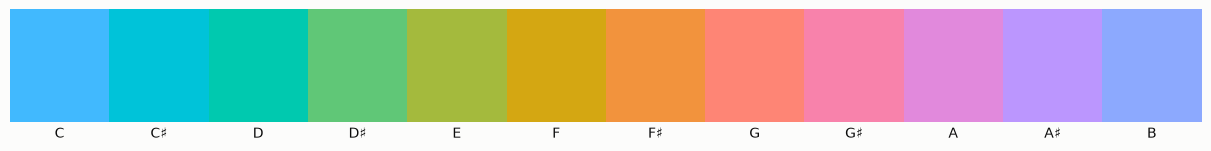

In [2]:
NOTES = ["C", "C♯", "D", "D♯", "E", "F", "F♯", "G", "G♯", "A", "A♯", "B"]
swatches = oklch_to_srgb(0.75, 0.15, pitch_class_hues())

fig, ax = plt.subplots(figsize=(12, 1.4), layout="constrained")
ax.imshow(swatches[None], aspect="auto", extent=[-0.5, 11.5, 0, 1])
ax.set_xticks(range(12), NOTES)
ax.set_yticks([])
ax.tick_params(axis="x", length=0, labelsize=10, labelcolor=INK)
ax.spines["bottom"].set_visible(False)
plt.show()

## Paleta de cada faixa

Uma tira por faixa, com o tempo na horizontal. A linha do meio de cada tira é a cor base de cada quadro; para cima e para baixo, os desvios de matiz das partículas, até ±15°. As tiras são cinza onde há silêncio.

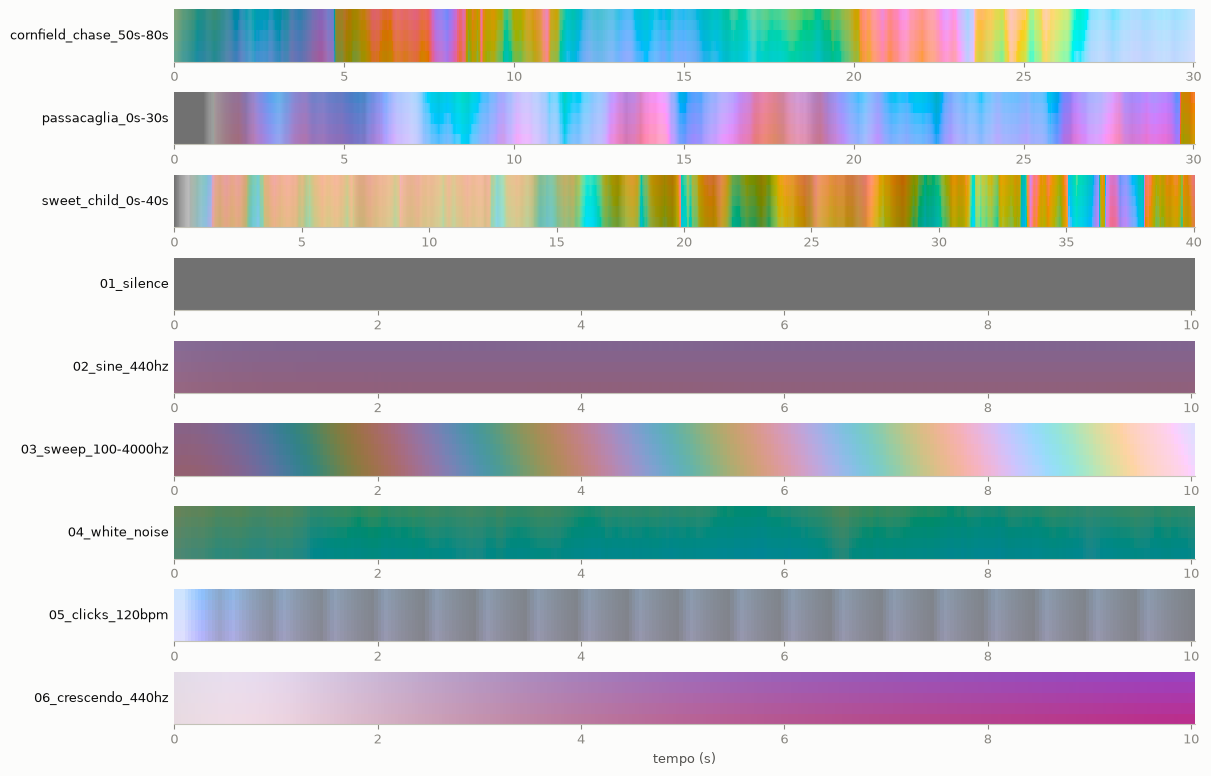

In [3]:
OFFSETS = np.array([-15, -7.5, 0, 7.5, 15])

fig, axes = plt.subplots(len(tracks), 1, figsize=(12, 0.85 * len(tracks)), layout="constrained")
for ax, path in zip(axes, tracks):
    c = colors[path.stem]
    strip = oklch_to_srgb(c["lightness"][None, :], c["chroma"][None, :], c["hue"][None, :] + OFFSETS[:, None])
    duration = len(c["hue"]) / config.fps
    ax.imshow(strip, aspect="auto", interpolation="nearest", extent=[0, duration, 0, 1])
    ax.set_yticks([])
    ax.set_ylabel(path.stem, rotation=0, ha="right", va="center", color=INK, fontsize=9)
    ax.set_xlim(0, duration)
axes[-1].set_xlabel("tempo (s)")
plt.show()